* **Author:** Elyse Owen
* **Date:** 16 November 2026
* **Class Title:** EDS220: Working with Environmental Data

## TASK 4: Visualizing fire Scars through false color

**Github Repository Link:** 
https://github.com/eowen19/eds220-hwk4

---
## About



### Readings

- NASA EARTH OBSERVATORY
- WHAT ARE THE BANDS DESIGNATION
- COmmon LANDSAT BAND COMBOS

### About the Data
This task will use two datasets:

**First dataset:Landsat Collection 2 Level-2 atmospherically:**
* Collection of bands (**red,green,blue,near-infrared and shortwave infared**)
  - `landsat8-2025-02-23-palisades-eaton.nc`
  
**Second dataset:Fire perimeters for the Eaton and Palisades fires:** 
- *More than one File*
  - `California_Fire_Perimeters_2017`

## Complete Workflow
---

In [1]:
# COMPLETE 

#import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 1. Import Libraries

In [2]:
# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import xarray as xr   
import rioxarray as rioaxr

## 1b. Import data

In [3]:
palisades = gpd.read_file(os.path.join('data', 
                                    'Palisades_Perimieter_20250121', 
                                    'Palisades_Perimieter_20250121.shp'))


eaton = gpd.read_file(os.path.join('data', 
                                    'Eaton_Perimeter_20250121', 
                                    'Eaton_Perimeter_20250121.shp'))


## 2. Fire perimeter data exploration
---
Explore the fire perimeter data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include, at least, the CRS of the data and whether this is projected or geographic.



In [4]:
print('Eaton CRS:', eaton.crs)
print('Palisades CRS:', palisades.crs)



Eaton CRS: EPSG:4269
Palisades CRS: EPSG:4269


The two fire perimeters have the same CRS (EPSG: 4269), a geographic CRS

## 3. NetCDF data import and exploration
---
Import the Landsat data using `xr.open_dataset()`.

a. Explore the data and write a brief summary of the information you obtained from the preliminary exploration.

b. Your summary should include a description of the data’s variables, dimensions, and coordinates.

In [5]:
fp = os.path.join('data', 'landsat8-2025-02-23-palisades-eaton.nc')
landsat = xr.open_dataset(fp)
landsat

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

The landsat dataset variables include the red, green, blue, nir08, swir22 bands as float32 data types, as well as a spatial_ref band as an int64. The dimensions are (y: 1418, x: 2742). The coordinates are x (int64), y(int64), and time(datetime64)

## 4. Restoring geospatial information


a.Use rio.crs to print the CRS of this dataset. Is this a geospatial object?

In [6]:
print('Landsat CRS:', landsat.rio.crs)

Landsat CRS: None


b.You may have noticed in section 3 that the geospatial information for this dataset is stored in the variable spatial_ref. Print the CRS by accessing the spatial_ref.crs_wkt attribute of the dataset.

In [7]:
print('Landsat Spatial Reference:', landsat.spatial_ref.crs_wkt)

Landsat Spatial Reference: PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


c. Recover the geospatial information by using rio.write_crs() and the spatial reference information from part b.


In [8]:
landsat = landsat.rio.write_crs(["EPSG","4326"])

d.Print the CRS of the updated dataset.

In [9]:
print('Landsat CRS:', landsat.rio.crs)

Landsat CRS: EPSG:4326


## 5. True color image

a. Without creating any new variables:
- select the red, green, and blue variables (in that order) of the xarray.Dataset holding the Landsat data,
- convert it to an xarray.DataArray using the to_dataarray() method, and then
- use .plot.imshow() to create an RGB image with the data. There will be a warning; that’s ok.

In [10]:
true_colour = landsat[['red', 'green', 'blue']].to_dataarray()
true_colour.plot.imshow()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


/opt/miniconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


b. Adjust the scale used for plotting the bands to get a true color image. HINT: Check the robust parameter.
To resolve the other warning, identify which bands have nan values. HINT: There are many ways of doing so. One option is to use numpy.isnan().

<xarray.DataArray ()> Size: 1B
array(True)
Coordinates:
    time         datetime64[ns] 8B ...
    spatial_ref  int64 8B 0

/opt/miniconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


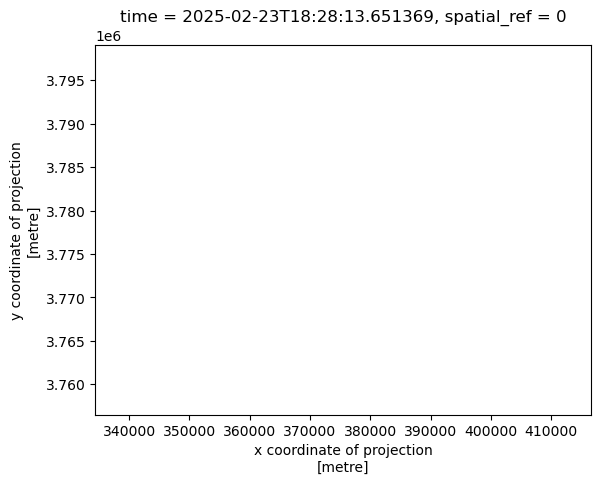

In [11]:
true_colour.isnull().any()

/opt/miniconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


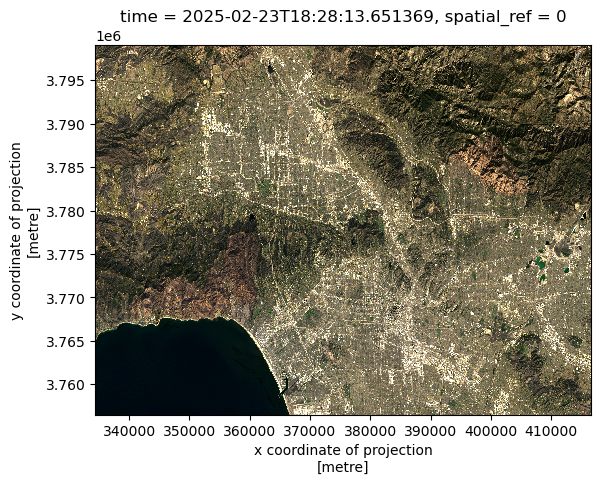

In [12]:
true_colour.plot.imshow(robust = True)

c. Use the .fillna() method for xarray.Datasets to replace any nan values in the Landsat data with zero.


In [13]:
true_colour.fillna(value = 0)

<xarray.DataArray (variable: 3, y: 1418, x: 2742)> Size: 47MB
array([[[10242.,  9886., 10142., ...,  8478.,  9179.,  9088.],
        [10338., 10263., 10255., ...,  8299.,  8645.,  8662.],
        [10312., 10153., 10300., ...,  9382.,  9123.,  8997.],
        ...,
        [ 7339.,  7334.,  7322., ..., 11020., 10743., 10067.],
        [ 7345.,  7336.,  7336., ..., 10899., 10877., 11075.],
        [ 7336.,  7330.,  7345., ..., 10327., 10188.,  9967.]],

       [[ 9930.,  9687.,  9894., ...,  8532.,  9138.,  8904.],
        [10046.,  9968.,  9925., ...,  8447.,  8679.,  8673.],
        [10026.,  9851.,  9944., ...,  9220.,  9069.,  8959.],
        ...,
        [ 7687.,  7699.,  7704., ..., 10526., 10417.,  9908.],
        [ 7686.,  7682.,  7685., ..., 10301., 10200., 10384.],
        [ 7699.,  7685.,  7686., ..., 10176.,  9984.,  9662.]],

       [[ 9290.,  9183.,  9344., ...,  8030.,  8352.,  8333.],
        [ 9374.,  9383.,  9338., ...,  7913.,  8110.,  8154.],
        [ 9369.,  9326.,  9367., ...,  8642.,  8434.,  8304.],
        ...,
        [ 7924.,  7921.,  7921., ...,  9976.,  9652.,  9260.],
        [ 7916.,  7910.,  7921., ...,  9487.,  9525.,  9803.],
        [ 7917.,  7904.,  7913., ...,  9624.,  9490.,  9187.]]],
      dtype=float32)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
  * variable     (variable) object 24B 'red' 'green' 'blue'

d. Create a new true color image that gets plotted without warnings.


/opt/miniconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


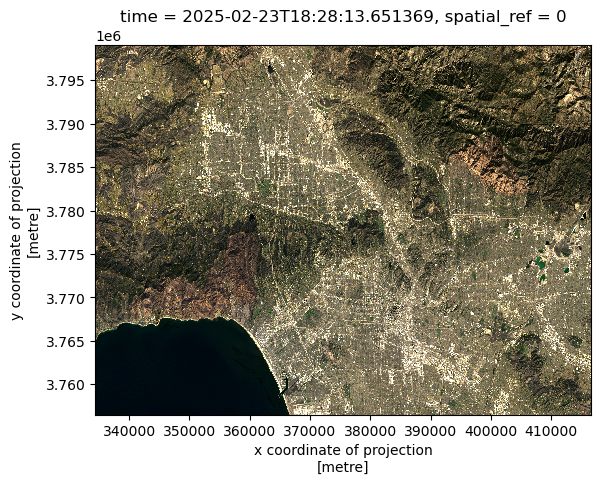

In [14]:
true_colour.plot.imshow(robust=True)

e. In a markdown cell write a brief explanation comparing the outputs for parts (a) and (d).

In section A, the image that is produced is blank and contains warning messages regarding the NAN values. In section D, the NAN values have been set to 0, and the robust parameter has been set to true. Setting the NAN values to 0 has removed the warnings, while setting the robust parameter to true has produced a true colour image that is reasonable.

## 6. False color image
Without creating any new variables, create a false color image by plotting the shortwave infrared (swir22), near-infrared, and red variables (in that order).

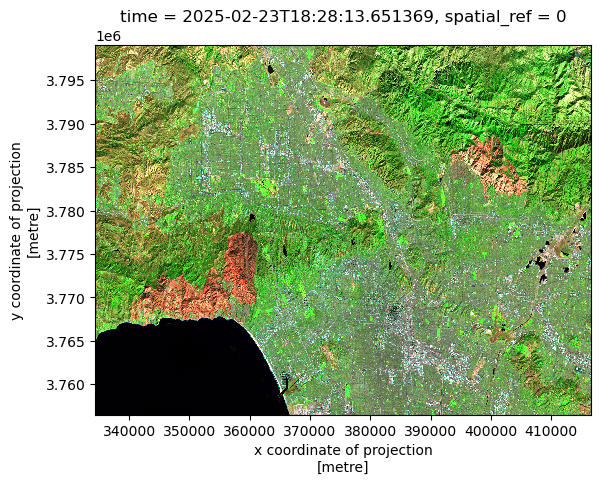

In [15]:
false_colour = landsat[['swir22', 'nir08', 'red']].to_dataarray()
false_colour.plot.imshow(robust = True)

## 7. Map
---

a. Create a map showing the shortwave infrared/near-infrared/red false color image together with both fire perimeters. Customize it appropriately including, at least, an informative title and legend. You may also want to include text on the map to identify which fire is which.

In [16]:
print('Eaton CRS:', eaton.crs)
print('Palisades CRS:', palisades.crs)
false_colour.rio.write_crs("EPSG:4269", inplace=True)


Eaton CRS: EPSG:4269
Palisades CRS: EPSG:4269


<xarray.DataArray (variable: 3, y: 1418, x: 2742)> Size: 47MB
array([[[14298., 14372., 14966., ...,  9612., 10777., 11166.],
        [14960., 14997., 15103., ...,  9136.,  9581.,  9991.],
        [15244., 14814., 15225., ..., 10644., 10606., 10683.],
        ...,
        [ 7302.,  7296.,  7299., ..., 15424., 14916., 13945.],
        [ 7309.,  7296.,  7311., ..., 14223., 14070., 13911.],
        [ 7299.,  7303.,  7307., ..., 14191., 14061., 13291.]],

       [[13306., 13132., 13282., ..., 14758., 15232., 15305.],
        [13532., 13480., 13409., ..., 13988., 14616., 15222.],
        [13669., 13479., 13422., ..., 14355., 14691., 13772.],
        ...,
        [ 7205.,  7211.,  7193., ..., 14567., 14091., 14088.],
        [ 7214.,  7208.,  7206., ..., 14303., 13981., 14440.],
        [ 7223.,  7212.,  7212., ..., 14271., 12870., 13063.]],

       [[10242.,  9886., 10142., ...,  8478.,  9179.,  9088.],
        [10338., 10263., 10255., ...,  8299.,  8645.,  8662.],
        [10312., 10153., 10300., ...,  9382.,  9123.,  8997.],
        ...,
        [ 7339.,  7334.,  7322., ..., 11020., 10743., 10067.],
        [ 7345.,  7336.,  7336., ..., 10899., 10877., 11075.],
        [ 7336.,  7330.,  7345., ..., 10327., 10188.,  9967.]]],
      dtype=float32)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
  * variable     (variable) object 24B 'swir22' 'nir08' 'red'
    spatial_ref  int64 8B 0

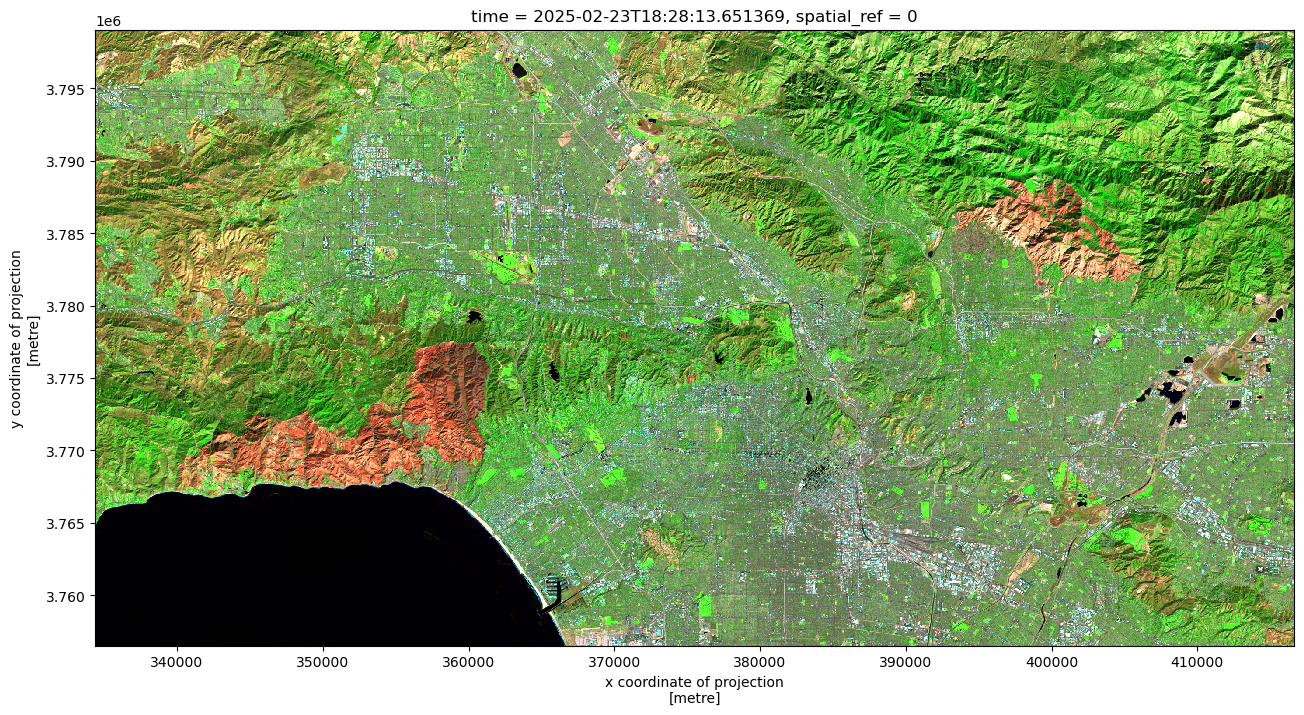

In [17]:
false_colour_aspect_ration = false_colour.rio.width/false_colour.rio.height
false_colour.plot.imshow(figsize=(8*false_colour_aspect_ration,8), robust=True)

In [18]:
assert eaton.crs == false_colour.rio.crs
assert palisades.crs == false_colour.rio.crs

In [19]:
print(eaton.crs)


EPSG:4269


In [20]:
print(eaton.crs)
print(false_colour.rio.crs)


EPSG:4269
EPSG:4269


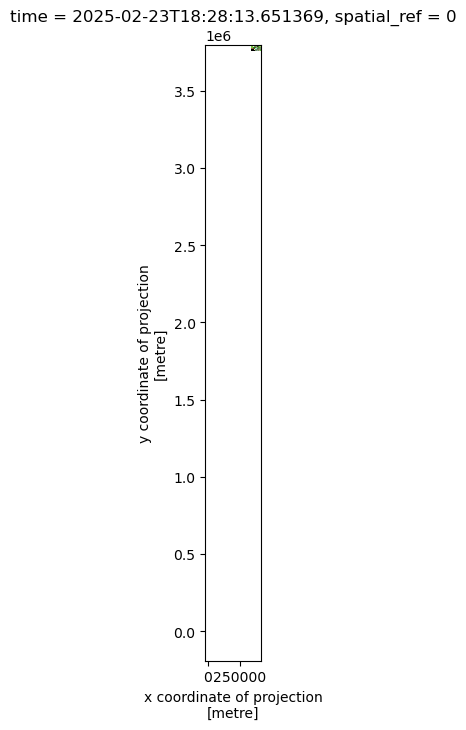

In [22]:
fig, ax = plt.subplots(figsize=(8*false_colour_aspect_ration, 8))
false_colour.plot.imshow(ax = ax, robust=True)
eaton.plot(ax = ax, alpha=0.6)
plt.show()

b. Write a figure description for the map including a brief explanation of how false color imagery is being used.

### Note:
The rest of the sections are about updating and cleaning your notebooks and repository. This is hugely important! By maintaining clean, well-structured repositories and notebooks, you’re not only showcasing your technical skills but also building a portfolio that reflects your professionalism, attention to detail, and ability to collaborate effectively with others.

Here is an example of an organized repository and notebook based on the oil spills task from homework 3.

## Clean your notebooks
---
The target audience for your notebooks is a fellow EDS 220 student who is just learning about wrangling raster data using Python.
- Add enough and appropriate comments to explain your code.
- Add enough and appropriate markdown cells to explain the procedures you are using and their output.
- The first cell in the notebook must be a markdown cell including:
- [ ] Title
- [ ]Author
- [ ] Link to GitHub repository containing the notebook (for grading purposes)

Each notebook must include an “About” section with the following subsections:
- [ ] Purpose: what is this notebook about?
- [ ] Highlights: List of highlights of analysis (3 or 4 highlights). What do you consider to be the most
- [ ] important aspects of this coding exercise?
- [ ] About the data: Datasets description
- [ ] References: Formal references to datasets. You can use the APA style as outlined here.

The rest of your notebook should be organized into logical subsections (indicated through markdown headers) for the analysis and visualization you are performing. The subsections should easily guide the reader through the analysis.

## Update your Repository
- [ ] `Title` Short, but descriptive title.
- [ ] `“About” section` A brief explanation of the repository’s purpose. Paragraphs or a bulleted list are both acceptable options. You may include an image or logo that represents the project.
- [ ] `“Repository Structure” section` A concise description of what’s housed in the repository. This includes information about the repository structure or file organization.
- [ ] `“Data” section` Details regarding data access. Any necessary information on where data lives (e.g. is it housed in the repo, on a server, in a library / package etc.) and how to access it in order to run the code.
- [ ] `“References” section`In an appropriate, consistent format, including links, provide a reference to the course and any other sources that supported the development of the repository. Include formal references to the datasets. You can use the APA style to cite data sources as outlined here.

##